### **CPU Quantization & Ablation Analysis**

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display
%load_ext autoreload
%autoreload 2
%cd ..
from src.config import QUANTIZATION_DIR
from src.utils.visualization import (
    load_quantization_reports,
    plot_quantization_ablation_dashboard,
    plot_quantization_curves,
)

EVAL_SPLIT = "val"
REPORTS_DIR = QUANTIZATION_DIR / "reports" / EVAL_SPLIT

results_df, metadata = load_quantization_reports(QUANTIZATION_DIR, eval_split=EVAL_SPLIT)

### **Environment, Calibration & Head Protection Provenance**

In [10]:
env = metadata.get("environment", {})
cal = metadata.get("calibration", {})
onnx_cfg = metadata.get("onnx_quantization", {})
excluded_map = onnx_cfg.get("excluded_nodes_by_resolution", {})

provenance_df = pd.DataFrame([
    {"Item": "Weights SHA256", "Value": metadata.get("source_weights_sha256")},
    {"Item": "Eval Split", "Value": metadata.get("eval_split")},
    {"Item": "Train-Only Calibration Images", "Value": f"{cal.get('actual_images')} (max={cal.get('max_images')}, seed={cal.get('seed')})"},
    {"Item": "ONNX PTQ Config", "Value": f"{onnx_cfg.get('format')} {onnx_cfg.get('activation_type')}/{onnx_cfg.get('weight_type')} per_channel={onnx_cfg.get('per_channel')} reduce_range={onnx_cfg.get('reduce_range')} ({onnx_cfg.get('calibrate_method')})"},
    {"Item": "Excluded ONNX Head Nodes", "Value": ", ".join(f"{k}: {len(v)}" for k, v in excluded_map.items())},
    {"Item": "CPU / Platform", "Value": f"{env.get('platform')} | {env.get('machine')} | cores={env.get('cpu_count')}"},
])
display(provenance_df.style.hide(axis="index"))

Item,Value
Weights SHA256,45c4525fcf9a8b18c81e2501a85829d639fd88ea364213988f351f8a37b4f263
Eval Split,val
Train-Only Calibration Images,"300 (max=300, seed=42)"
ONNX PTQ Config,QDQ QUInt8/QInt8 per_channel=True reduce_range=False (MinMax)
Excluded ONNX Head Nodes,"1280: 66, 640: 66"
CPU / Platform,Windows-10-10.0.19045-SP0 | AMD64 | cores=8


### **Stage-by-Stage Size, CPU Speed & Threshold-Free Quality**

In [5]:
main_cols = [
    "imgsz",
    "stage",
    "size_mb",
    "compute_mean_ms",
    "compute_fps",
    "e2e_mean_ms",
    "e2e_p95_ms",
    "e2e_fps",
    "rss_mb",
    "mAP50",
    "mAP50-95",
    "AP50",
    "AP50_small",
    "Recall_small (raw)",
    "Neg FPR @ R>=0.85 (%)",
    "Mean Neg FA Rate (%)",
    "tp_conf_median",
    "tp_recall_ge_0_30",
]
present_main = [col for col in main_cols if col in results_df.columns]
display(
    results_df[present_main]
    .style
    .format(precision=4, na_rep="-")
    .hide(axis="index")
)

imgsz,stage,size_mb,compute_mean_ms,compute_fps,e2e_mean_ms,e2e_p95_ms,e2e_fps,rss_mb,mAP50,mAP50-95,AP50,AP50_small,Recall_small (raw),Neg FPR @ R>=0.85 (%),Mean Neg FA Rate (%),tp_conf_median,tp_recall_ge_0_30
1280,pytorch_fp32,5.2475,1380.6653,0.7243,1566.1157,1821.7701,0.6385,0.0000,-,-,-,-,-,-,-,-,-
1280,onnx_fp32,9.8318,306.4330,3.2634,381.7766,418.5084,2.6193,0.0000,0.9590,0.8200,0.9508,0.9132,0.9623,4.0541,22.8638,0.9757,0.9399
1280,onnx_int8,3.4752,354.7136,2.8192,583.2099,1353.2113,1.7146,0.0000,0.9018,0.7162,0.8787,0.8772,0.9434,16.2162,6.1971,0.8227,0.8357
1280,openvino_fp32,9.8131,269.2485,3.7140,537.9977,962.3361,1.8587,0.0000,0.9600,0.8176,0.9523,0.9175,0.9623,5.4054,22.9730,0.9751,0.9399
1280,openvino_int8,3.4751,137.9866,7.2471,600.7998,946.8834,1.6644,0.0000,0.9547,0.7952,0.9502,0.9397,0.9811,6.7568,20.7207,0.9751,0.9375
640,pytorch_fp32,5.2475,146.1822,6.8408,164.8197,207.4396,6.0672,0.0000,-,-,-,-,-,-,-,-,-
640,onnx_fp32,9.3508,73.1139,13.6773,102.9294,118.4068,9.7154,0.0000,0.7821,0.6280,0.7578,0.2564,0.2642,-,1.2558,0.9515,0.6893
640,onnx_int8,2.9942,58.2485,17.1678,90.7592,107.2237,11.0182,0.0000,0.7285,0.5577,0.6795,0.2439,0.2453,-,0.7235,0.5000,0.4655
640,openvino_fp32,9.5243,59.7604,16.7335,177.1497,259.6328,5.6449,0.0000,0.7824,0.6274,0.7571,0.2591,0.2642,-,1.2558,0.9517,0.6887
640,openvino_int8,3.1863,25.9231,38.5757,81.3548,115.8429,12.2918,0.0000,0.8057,0.6280,0.7821,0.4281,0.4528,-,1.1193,0.9517,0.7125


### **Quantization Deltas (FP32 -> INT8 Within Resolution) & Speedups**

In [6]:
delta_cols = [
    "imgsz",
    "stage",
    "size_ratio_vs_pt",
    "size_reduction_pct_vs_fp32",
    "speedup_compute_vs_fp32",
    "speedup_e2e_vs_pt",
    "ap50_delta_vs_fp32",
    "ap50_small_delta_vs_fp32",
    "map50_delta_vs_fp32",
    "map50_95_delta_vs_fp32",
    "neg_fpr_at_r85_delta_vs_fp32",
]
present_deltas = [col for col in delta_cols if col in results_df.columns]
display(
    results_df[present_deltas]
    .style
    .format(precision=4, na_rep="-")
    .hide(axis="index")
)

imgsz,stage,size_ratio_vs_pt,size_reduction_pct_vs_fp32,speedup_compute_vs_fp32,speedup_e2e_vs_pt,ap50_delta_vs_fp32,ap50_small_delta_vs_fp32,map50_delta_vs_fp32,map50_95_delta_vs_fp32,neg_fpr_at_r85_delta_vs_fp32
1280,pytorch_fp32,1.0000,-,-,1.0000,-,-,-,-,-
1280,onnx_fp32,1.8736,-,-,4.1022,-,-,-,-,-
1280,onnx_int8,0.6623,64.6532,0.8639,2.6853,-0.0722,-0.0359,-0.0571,-0.1038,12.1622
1280,openvino_fp32,1.8700,-,-,2.9110,-,-,-,-,-
1280,openvino_int8,0.6622,64.5867,1.9513,2.6067,-0.0022,0.0222,-0.0053,-0.0224,1.3514
640,pytorch_fp32,1.0000,-,-,1.0000,-,-,-,-,-
640,onnx_fp32,1.7819,-,-,1.6013,-,-,-,-,-
640,onnx_int8,0.5706,67.9788,1.2552,1.8160,-0.0783,-0.0125,-0.0537,-0.0703,-
640,openvino_fp32,1.8150,-,-,0.9304,-,-,-,-,-
640,openvino_int8,0.6072,66.5458,2.3053,2.0259,0.0250,0.1690,0.0233,0.0006,-


### **Scale-Stratified Breakdown (Small / Medium / Large)**

In [7]:
scale_rows = []
for key, detail in (metadata.get("stage_details") or {}).items():
    stage_name, _, res_str = key.rpartition("_")
    for entry in detail.get("by_scale", []):
        scale_rows.append({"imgsz": int(res_str), "stage": stage_name, **entry})

if scale_rows:
    scale_df = pd.DataFrame(scale_rows).sort_values(["imgsz", "Scale", "stage"], ascending=[False, True, True])
    display(scale_df.style.format(precision=4, na_rep="-").hide(axis="index"))

imgsz,stage,Scale,GT,AP50,Max Recall (raw),Recall @ Max-F1,Recall @ Neg FPR<=5%
1280,onnx_fp32,large,1150,0.9751,0.9783,0.9635,0.8991
1280,onnx_int8,large,1150,0.9011,0.9139,0.9130,0.4704
1280,openvino_fp32,large,1150,0.9756,0.9783,0.9565,0.8887
1280,openvino_int8,large,1150,0.9720,0.9774,0.9557,0.8861
1280,onnx_fp32,medium,477,0.8917,0.9057,0.8679,0.7547
1280,onnx_int8,medium,477,0.8359,0.8553,0.8491,0.7463
1280,openvino_fp32,medium,477,0.8948,0.9099,0.8658,0.7233
1280,openvino_int8,medium,477,0.8947,0.9140,0.8721,0.7652
1280,onnx_fp32,small,53,0.9132,0.9623,0.9623,0.6792
1280,onnx_int8,small,53,0.8772,0.9434,0.9245,0.8302


### **Ablation Dashboard & Threshold-Free Trade-Off Curves**

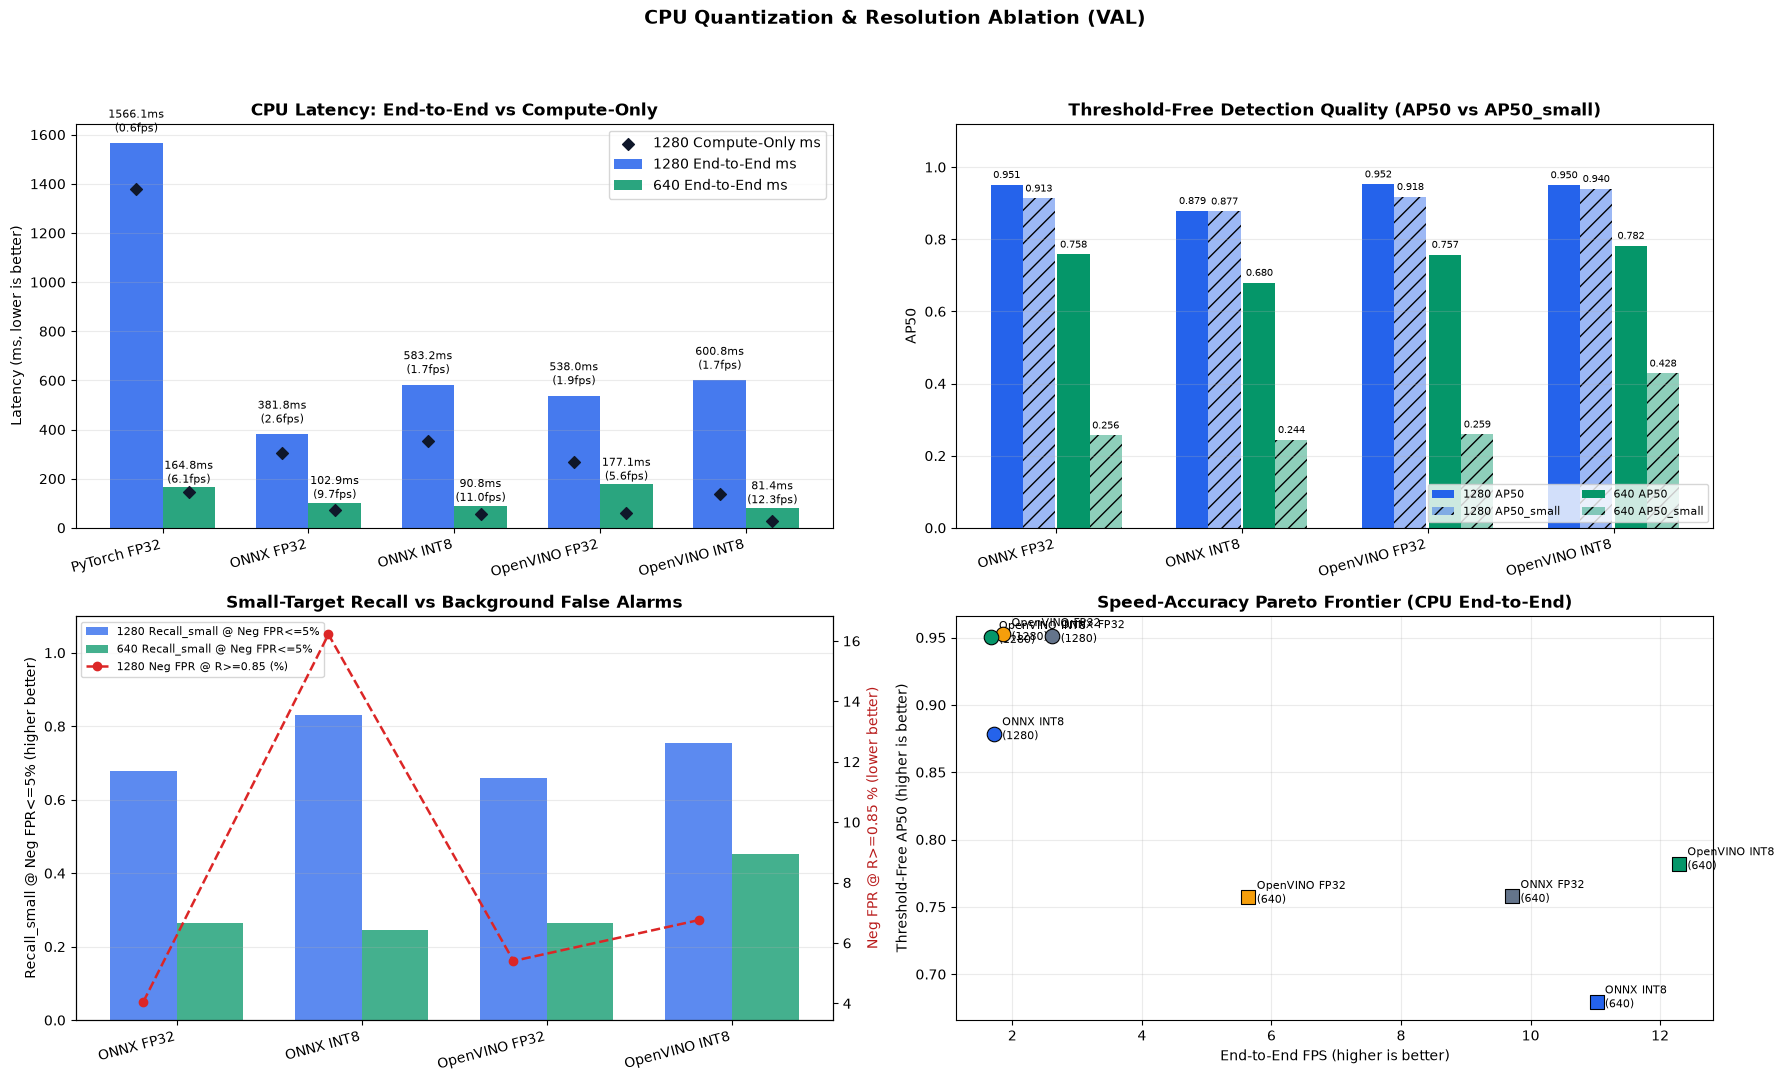

In [8]:
plot_quantization_ablation_dashboard(
    results_df,
    metadata,
    save_path=REPORTS_DIR / "quantization_ablation_dashboard.png",
)

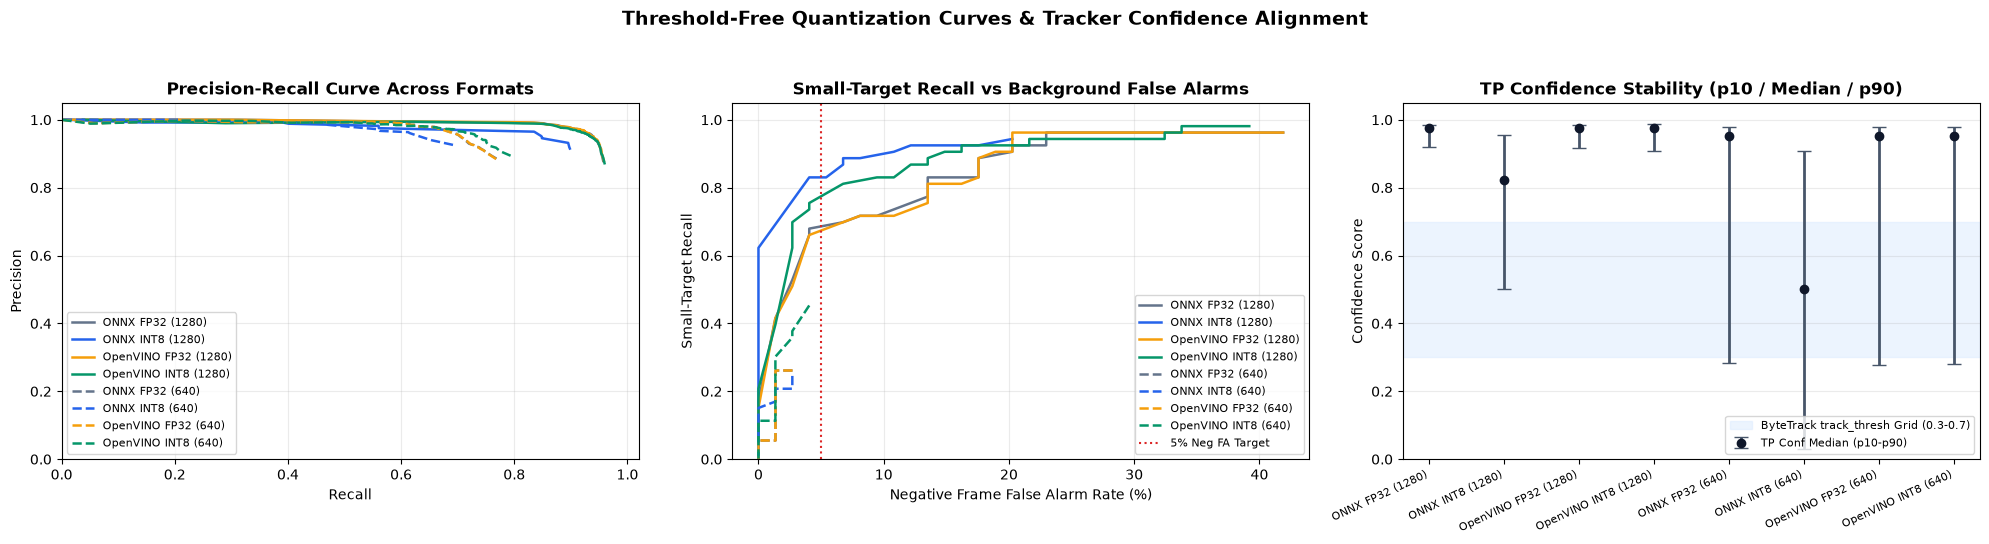

In [9]:
plot_quantization_curves(
    metadata,
    save_path=REPORTS_DIR / "quantization_curves.png",
)